# Clima e produção agrícola em Itapeva-SP
**SafraViva · Fase 2: análise exploratória**

Itapeva é o maior produtor de grãos do Sudoeste Paulista. Este notebook cruza **52 anos de produção municipal (IBGE/PAM)**
com **45 anos de clima diário (NASA POWER)**, **20 anos da estação do INMET em Itapeva (A714)** e o **zoneamento de risco
climático (ZARC/MAPA)** para responder a três perguntas:

1. Como Itapeva se tornou referência regional, e quanto ela produz a mais que SP e PR?
2. O que o clima explica (e o que não explica) nas safras ruins?
3. O que isso muda na decisão do produtor: quando plantar, quando se preocupar com geada e veranico?

> Os dados são carregados pelo ETL (`python -m scripts.rodar_etl`), e as consultas SQL estão em `sql/analises/`.

In [1]:
import os, sys
from pathlib import Path
raiz = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(raiz); sys.path.insert(0, str(raiz))

import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from analytics import viz, modelo_rendimento as modelo
from core import config

con = duckdb.connect(str(config.CAMINHO_DB), read_only=True)
sql = lambda q, *p: con.execute(q, list(p)).df()
FIG = raiz / "docs" / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
viz.aplicar_estilo()
pd.set_option("display.max_columns", 20)

## 1. Itapeva produz mais por hectare que SP e PR, e a diferença se consolidou nos anos 2000
Média móvel de 5 anos do rendimento da soja. Os anos com valor repetido pelo informante municipal ficam de fora
(flag `suspeito_repeticao`, ver `docs/fontes.md`).

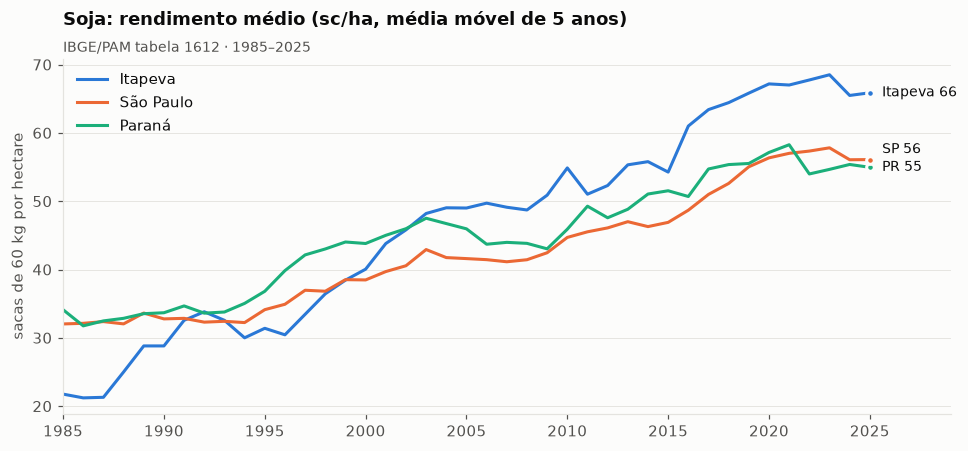

,cultura,itapeva_mm5,sp_mm5,pr_mm5,vantagem_vs_sp_pct
5,milho,121.4,93.4,91.3,30.0
11,soja,65.9,56.1,55.0,17.0
17,trigo,58.3,50.0,46.9,17.0


In [2]:
mm5 = sql('''
    WITH s AS (
        SELECT ano,
               max(rendimento_sc_ha) FILTER (WHERE nivel='municipio' AND codigo_local=3522406 AND NOT suspeito_repeticao) AS Itapeva,
               max(rendimento_sc_ha) FILTER (WHERE nivel='uf' AND codigo_local=35) AS SP,
               max(rendimento_sc_ha) FILTER (WHERE nivel='uf' AND codigo_local=41) AS PR
        FROM analytics.fato_producao WHERE cultura='soja' GROUP BY ano)
    SELECT ano,
           avg(Itapeva) OVER w AS Itapeva, avg(SP) OVER w AS SP, avg(PR) OVER w AS PR
    FROM s WINDOW w AS (ORDER BY ano ROWS BETWEEN 4 PRECEDING AND CURRENT ROW)
    ORDER BY ano''').query("ano >= 1985")

fig, ax = viz.nova_figura()
nomes = {"Itapeva": "Itapeva", "SP": "São Paulo", "PR": "Paraná"}
rotulos = []
for local in ["Itapeva", "SP", "PR"]:
    ax.plot(mm5.ano, mm5[local], color=viz.CORES_LOCAL[local], label=nomes[local])
    ultimo = mm5.dropna(subset=[local]).iloc[-1]
    rotulos.append((ultimo.ano, ultimo[local], f"{local} {ultimo[local]:.0f}", viz.CORES_LOCAL[local]))
ax.set_title("Soja: rendimento médio (sc/ha, média móvel de 5 anos)", pad=22)
viz.subtitulo(ax, "IBGE/PAM tabela 1612 · 1985–2025")
ax.set_xlim(1985, 2029); ax.set_ylabel("sacas de 60 kg por hectare")
ax.legend(loc="upper left")
viz.rotulos_finais(ax, rotulos)
fig.tight_layout(); fig.savefig(FIG / "01_soja_itapeva_sp_pr.png"); plt.show()

vant = sql(open("sql/analises/03_itapeva_vs_estados.sql", encoding="utf-8").read())
vant[vant.ano == 2025][["cultura", "itapeva_mm5", "sp_mm5", "pr_mm5", "vantagem_vs_sp_pct"]]

**Leitura:** até os anos 1990, Itapeva produzia *menos* que a média paulista. A virada veio nos anos 2000, com o plantio
direto sobre palha e a sucessão soja–trigo. Hoje o município produz **~17% mais soja, ~30% mais milho e ~17% mais trigo
por hectare que a média de SP**.

## 2. A expansão: a soja multiplicou a área por 20 em 25 anos, e o trigo virou a cultura de inverno

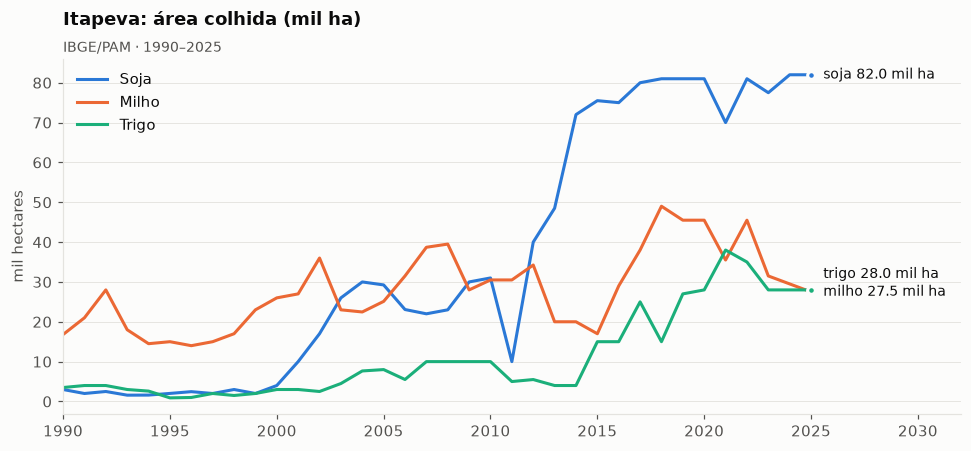

,cultura,nome_local,area_media_ha,participacao_regiao_pct,rank_area,rendimento_sc_ha,rank_rendimento
0,milho,Itapeva (SP),33900.0,27.9,1,121.4,2
11,soja,Itapeva (SP),78500.0,30.9,1,65.9,5
22,trigo,Itapeva (SP),31400.0,32.8,1,58.3,1


In [3]:
area = sql('''
    SELECT ano, cultura, area_colhida_ha FROM analytics.fato_producao
    WHERE nivel='municipio' AND codigo_local=3522406 AND cultura IN ('soja','milho','trigo') AND ano >= 1990
    ORDER BY ano''').pivot(index="ano", columns="cultura", values="area_colhida_ha") / 1000

cores = {"soja": viz.SERIE[0], "milho": viz.SERIE[1], "trigo": viz.SERIE[2]}
fig, ax = viz.nova_figura()
rotulos = []
for cultura in ["soja", "milho", "trigo"]:
    ax.plot(area.index, area[cultura], color=cores[cultura], label=cultura.capitalize())
    rotulos.append((area.index[-1], area[cultura].iloc[-1], f"{cultura} {area[cultura].iloc[-1]:.1f} mil ha", cores[cultura]))
ax.set_title("Itapeva: área colhida (mil ha)", pad=22)
viz.subtitulo(ax, "IBGE/PAM · 1990–2025")
ax.set_xlim(1990, 2032); ax.set_ylabel("mil hectares"); ax.legend(loc="upper left")
viz.rotulos_finais(ax, rotulos)
fig.tight_layout(); fig.savefig(FIG / "02_area_itapeva.png"); plt.show()

sql(open("sql/analises/02_ranking_regional.sql", encoding="utf-8").read()).query("nome_local == 'Itapeva (SP)'")

**Leitura:** a soja saiu de **4 mil ha (2000) para 82 mil ha (2025)**, um crescimento de 12,8% ao ano. O trigo foi de 3 mil
para 28 mil ha. Itapeva responde sozinha por **~31% da soja, ~28% do milho e ~33% do trigo** dos 11 municípios da região.

## 3. O verão está ficando mais quente: o calor extremo triplicou na década atual
Série homogênea NASA POWER no centroide de Itapeva. O verão da safra vai de outubro a março.

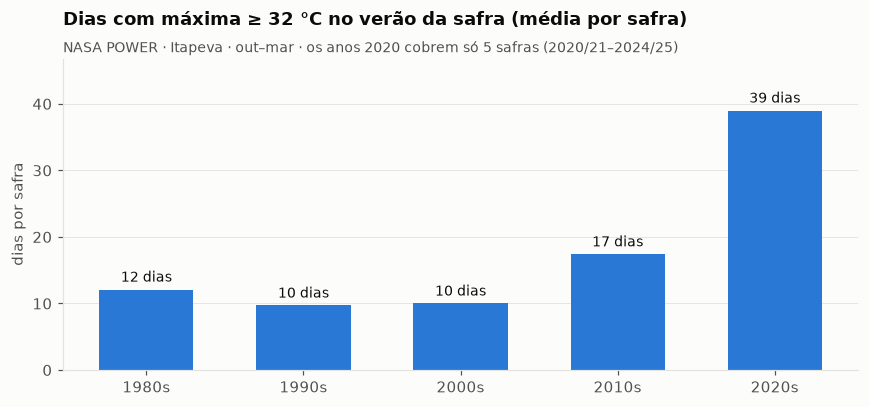

,decada,safras,chuva_verao_mm,tmax_verao_c,dias_ge32_verao,tmin_inverno_c,dias_le3_inverno
0,1980s,9,948.0,27.3,12.1,10.5,1.2
1,1990s,10,1028.0,27.1,9.7,10.8,1.9
2,2000s,10,945.0,27.4,10.0,11.0,1.5
3,2010s,10,896.0,27.8,17.4,11.3,1.0
4,2020s,5,711.0,29.2,39.0,11.3,1.6


In [4]:
tend = sql(open("sql/analises/08_tendencia_climatica.sql", encoding="utf-8").read())
fig, ax = viz.nova_figura(8, 3.8)
barras = ax.bar(tend.decada, tend.dias_ge32_verao, color=viz.SERIE[0], width=0.6)
ax.bar_label(barras, labels=[f"{v:.0f} dias" for v in tend.dias_ge32_verao], padding=3, color=viz.TEXTO, fontsize=9)
ax.set_title("Dias com máxima ≥ 32 °C no verão da safra (média por safra)", pad=22)
viz.subtitulo(ax, "NASA POWER · Itapeva · out–mar · os anos 2020 cobrem só 5 safras (2020/21–2024/25)")
ax.set_ylabel("dias por safra"); ax.set_ylim(0, tend.dias_ge32_verao.max() * 1.2)
fig.tight_layout(); fig.savefig(FIG / "03_calor_por_decada.png"); plt.show()
tend

**Leitura:** a década de 2020 (até agora) tem em média **~39 dias com máxima ≥ 32 °C** no verão, contra 10 a 17 nas
décadas anteriores, e **~25% menos chuva** de outubro a março. São só 5 safras, que incluem o El Niño quente de 2023/24,
então o número vai oscilar. Mesmo assim, a direção é a mesma das estações vizinhas e pesa no florescimento da soja.

## 4. Safras ruins: o que o clima explica
Desvio do rendimento em relação à média dos 5 anos anteriores (soja, Itapeva). Azul é safra acima da tendência, vermelho
abaixo.

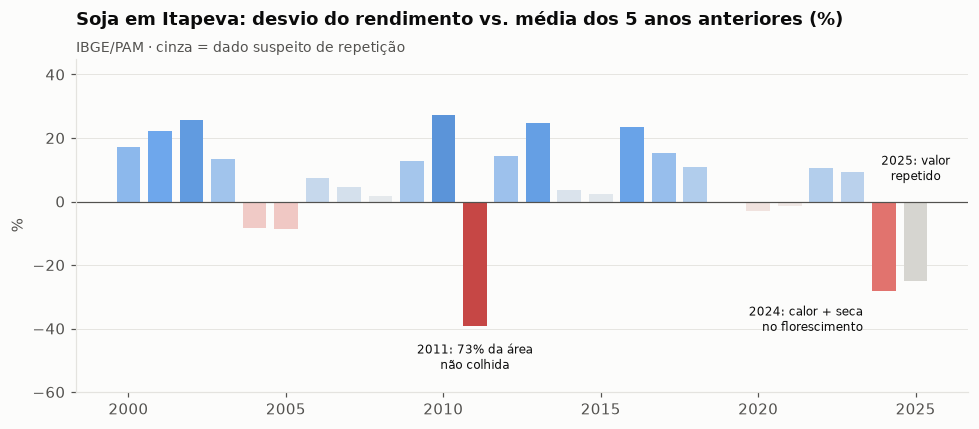

,cultura,ano,sc_ha,desvio_pct,chuva_flor_mm,balanco_flor_mm,veranico_max_dias,dias_calor_flor,tmin_ciclo_c,chuva_colheita_mm
0,milho,1994,36.0,-28.0,153.0,-9.0,4,2,9.3,210.0
1,milho,2011,38.8,-67.0,259.0,89.0,7,1,10.0,130.0
2,soja,1983,15.2,-29.0,260.0,NaN,2,0,10.6,263.0
3,soja,1993,25.0,-29.0,264.0,124.0,5,4,10.4,165.0
4,soja,2011,33.3,-39.0,288.0,141.0,14,3,10.0,128.0
5,soja,2024,49.2,-28.0,95.0,-45.0,9,13,10.5,103.0
6,trigo,1984,10.0,-47.0,108.0,-2.0,11,0,1.2,109.0
7,trigo,1990,16.8,-28.0,247.0,142.0,19,0,-0.1,166.0
8,trigo,1994,16.7,-21.0,29.0,-117.0,36,3,-1.7,191.0
9,trigo,1996,16.7,-24.0,56.0,-74.0,14,0,4.1,218.0


In [5]:
soja = sql('''
    SELECT ano, desvio_vs_media_5a*100 AS desvio, suspeito_repeticao, perda_area_pct
    FROM analytics.fato_producao
    WHERE nivel='municipio' AND codigo_local=3522406 AND cultura='soja' AND ano >= 2000 ORDER BY ano''')
lim = 45
cores_barra = [viz.DIVERGENTE(0.5 + np.clip(-d, -lim, lim) / (2 * lim)) if not s else "#d6d5d0"
               for d, s in zip(soja.desvio.fillna(0), soja.suspeito_repeticao)]
fig, ax = viz.nova_figura(9, 4)
ax.bar(soja.ano, soja.desvio, color=cores_barra, width=0.75)
ax.axhline(0, color=viz.TEXTO_2, linewidth=0.8)
desvio = soja.set_index("ano").desvio
notas = [  # (ano, y âncora, deslocamento em pontos, alinhamento, texto)
    (2011, desvio[2011], (0, -28), "center", "2011: 73% da área\nnão colhida"),
    (2024, desvio[2024], (-14, -26), "right", "2024: calor + seca\nno florescimento"),
    (2025, 0, (0, 14), "center", "2025: valor\nrepetido"),
]
for ano, y, desloc, alinhamento, texto in notas:
    ax.annotate(texto, (ano, y), xytext=desloc, textcoords="offset points", ha=alinhamento, fontsize=8, color=viz.TEXTO)
ax.set_title("Soja em Itapeva: desvio do rendimento vs. média dos 5 anos anteriores (%)", pad=22)
viz.subtitulo(ax, "IBGE/PAM · cinza = dado suspeito de repetição")
ax.set_ylim(-60, 45); ax.set_ylabel("%")
fig.tight_layout(); fig.savefig(FIG / "04_quebras_soja.png"); plt.show()

sql(open("sql/analises/05_anos_de_quebra.sql", encoding="utf-8").read())

**Leitura:**
* **Soja 2024 (−28%):** é a quebra com assinatura climática mais clara. O florescimento (janeiro) teve **13 dias ≥ 32 °C**
  e balanço hídrico negativo, o típico estresse do El Niño 2023/24.
* **Trigo 1994, 2000 e 2019:** geada (Tmín de −1,7 °C e −1,5 °C na grade NASA) ou seca no florescimento (veranico de 33–36 dias).
  O trigo de 2009 sofreu com **285 mm de chuva na colheita**, o que causa germinação na espiga.
* **Soja e milho 2011:** perda de área de 73% (soja) e rendimento de milho −67%, sem sinal climático na estação A714.
  A causa **não foi identificada** nos dados públicos (pode ser sanidade, granizo localizado ou erro de registro), e isso
  fica marcado para checagem com produtores e a CATI.

## 5. Geada: o risco é concentrado em junho e julho e nunca chegou a 0 °C no abrigo
Estação A714, 2006 a 2026. No abrigo meteorológico (a 1,5–2 m), **≤ 3 °C** costuma significar geada na relva.

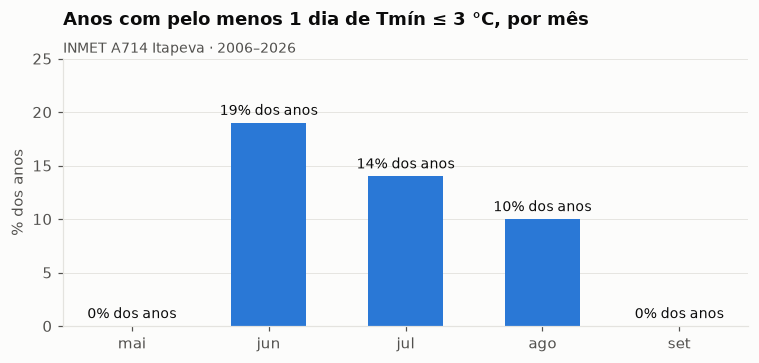

,mes,dias_tmin_le3,dias_tmin_le1,media_dias_por_ano,pct_anos_com_evento,tmin_absoluta_c
0,5,0,0,0.00,0.0,3.7
1,6,5,0,0.24,19.0,1.4
2,7,6,2,0.29,14.0,0.1
3,8,2,0,0.10,10.0,2.5
4,9,0,0,0.00,0.0,3.9


In [6]:
geada = sql(open("sql/analises/06_geada_por_mes.sql", encoding="utf-8").read())
meses = {5: "mai", 6: "jun", 7: "jul", 8: "ago", 9: "set"}
fig, ax = viz.nova_figura(7, 3.4)
barras = ax.bar(geada.mes.map(meses), geada.pct_anos_com_evento, color=viz.SERIE[0], width=0.55)
ax.bar_label(barras, labels=[f"{v:.0f}% dos anos" for v in geada.pct_anos_com_evento], padding=3, fontsize=9, color=viz.TEXTO)
ax.set_title("Anos com pelo menos 1 dia de Tmín ≤ 3 °C, por mês", pad=22)
viz.subtitulo(ax, "INMET A714 Itapeva · 2006–2026")
ax.set_ylim(0, 25); ax.set_ylabel("% dos anos")
fig.tight_layout(); fig.savefig(FIG / "05_geada_por_mes.png"); plt.show()
geada

**Leitura:** julho é o mês mais perigoso (mínima absoluta de **0,1 °C em 2021**), seguido de junho. É exatamente o
**perfilhamento e o espigamento do trigo semeado em abril e maio**. O modelo do item 7 confirma que cada dia ≤ 3 °C no
florescimento do trigo custa produtividade.

## 6. Janela de plantio da soja, safra 2026/27 (ZARC)
Risco climático por classe de água disponível no solo (AD1 = arenoso, AD6 = maior retenção), Grupo II, sequeiro.

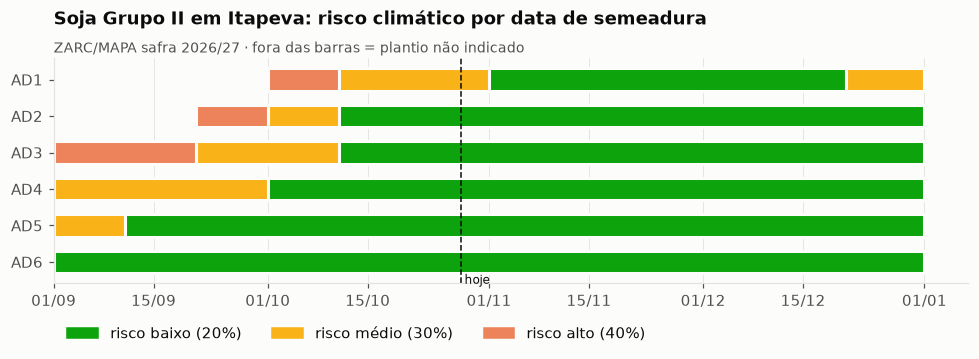

In [7]:
jan = sql('''
    SELECT solo, cod_solo, nivel_risco, data_inicio, data_fim
    FROM analytics.janela_plantio
    WHERE codigo_ibge=3522406 AND safra='2026-2027' AND nome_cultura='Soja' AND ciclo='Grupo II' AND manejo='Sequeiro'
    ORDER BY cod_solo, data_inicio''')
cor_risco = {"baixo": "#0ca30c", "médio": "#fab219", "alto": "#ec835a"}  # paleta de status (sempre com rótulo)
solos = sorted(jan.solo.unique(), key=lambda s: int(s[2:]))
fig, ax = viz.nova_figura(9, 3.6)
for i, solo in enumerate(solos):
    for _, j in jan[jan.solo == solo].iterrows():
        ini, fim = pd.Timestamp(j.data_inicio), pd.Timestamp(j.data_fim) + pd.Timedelta(days=1)
        ax.barh(i, (fim - ini).days, left=ini, height=0.62, color=cor_risco[j.nivel_risco], edgecolor=viz.SUPERFICIE, linewidth=2)
ax.axvline(pd.Timestamp.today().normalize(), color=viz.TEXTO, linewidth=1, linestyle="--")
ax.text(pd.Timestamp.today().normalize(), len(solos) - 0.4, " hoje", fontsize=8, color=viz.TEXTO)
ax.set_yticks(range(len(solos)), solos); ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.grid(axis="x")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d/%m"))
ax.set_title("Soja Grupo II em Itapeva: risco climático por data de semeadura", pad=22)
viz.subtitulo(ax, "ZARC/MAPA safra 2026/27 · fora das barras = plantio não indicado")
ax.legend(handles=[Patch(color=c, label=f"risco {k} ({ {'baixo': 20, 'médio': 30, 'alto': 40}[k] }%)") for k, c in cor_risco.items()],
          loc="lower left", ncol=3, bbox_to_anchor=(0, -0.32))
fig.tight_layout(); fig.savefig(FIG / "06_janela_soja_zarc.png"); plt.show()

**Leitura:** em solos de boa retenção (AD4–AD6), a janela de risco baixo cobre **outubro a dezembro**. Em solos arenosos (AD1),
plantar em outubro ainda é risco médio ou alto, e o ideal é **novembro**. Para encaixar milho safrinha depois (risco baixo
até ~20/jan em AD4), a soja precisa ser precoce e semeada em outubro.

## 7. Quanto o clima explica a produtividade? Modelo em painel com 11 municípios
`log(rendimento) ~ efeito do município + tendência + índices por fase`, com erros agrupados por ano. A validação é temporal
(o modelo só vê o passado) e compara com uma base sem clima.

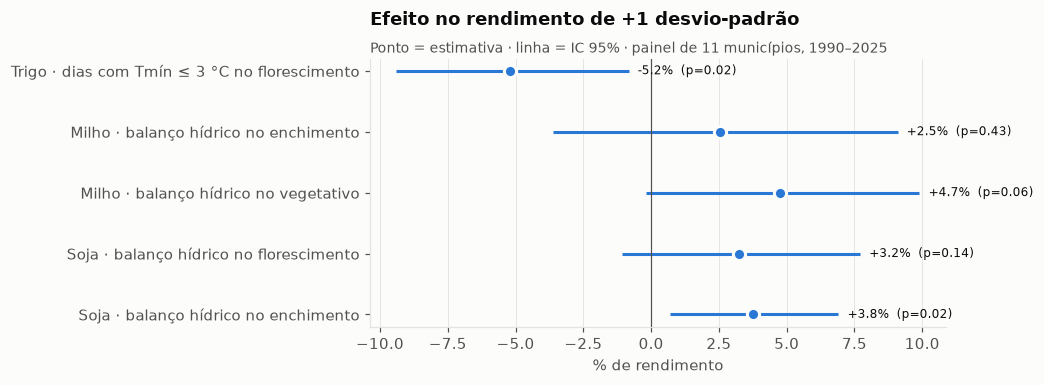

,cultura,observações,ganho tecnológico %/ano,R² base,R² com clima,erro fora da amostra (base) %,erro (com clima) %
0,soja,211,2.31,0.52,0.54,16.27,16.31
1,milho,344,3.18,0.64,0.65,29.42,29.22
2,trigo,187,2.45,0.45,0.47,25.80,24.89


In [8]:
linhas, coefs = [], []
for cultura in ["soja", "milho", "trigo"]:
    r = modelo.ajustar(con, cultura)
    v = modelo.resumo_validacao(r)
    linhas.append({"cultura": cultura, "observações": len(r.dados), "ganho tecnológico %/ano": 100 * r.modelo.params["ano"],
                   "R² base": r.base.rsquared, "R² com clima": r.modelo.rsquared,
                   "erro fora da amostra (base) %": v.erro_medio_base_pct, "erro (com clima) %": v.erro_medio_clima_pct})
    coefs.append(r.coeficientes.assign(cultura=cultura))
resumo = pd.DataFrame(linhas).round(2); coefs = pd.concat(coefs)

fig, ax = viz.nova_figura(9.5, 3.6)
coefs = coefs.reset_index(drop=True)
nome_indice = {"balanco_mm": "balanço hídrico", "dias_tmin_le3": "dias com Tmín ≤ 3 °C"}
rotulos = [f"{c.capitalize()} · {nome_indice[i.split('__')[0]]} no {i.split('__')[1]}" for c, i in zip(coefs.cultura, coefs.indice)]
y = np.arange(len(coefs))
ax.hlines(y, coefs.ic95_inf_pct, coefs.ic95_sup_pct, color=viz.SERIE[0], linewidth=2)
ax.plot(coefs.efeito_1dp_pct, y, "o", color=viz.SERIE[0], markersize=8, markeredgecolor=viz.SUPERFICIE, markeredgewidth=2)
for yi, (e, p) in enumerate(zip(coefs.efeito_1dp_pct, coefs.p_valor)):
    ax.annotate(f"{e:+.1f}%  (p={p:.2f})", (coefs.ic95_sup_pct[yi], yi), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8, color=viz.TEXTO)
ax.axvline(0, color=viz.TEXTO_2, linewidth=0.8)
ax.set_yticks(y, rotulos); ax.grid(axis="y", visible=False); ax.grid(axis="x")
ax.set_title("Efeito no rendimento de +1 desvio-padrão", pad=22)
viz.subtitulo(ax, "Ponto = estimativa · linha = IC 95% · painel de 11 municípios, 1990–2025")
ax.set_xlabel("% de rendimento")
fig.tight_layout(); fig.savefig(FIG / "07_efeitos_clima.png"); plt.show()
resumo

**Leitura (honesta):**
* O **ganho tecnológico** domina: de +2,3% a +3,3% ao ano de rendimento, por si só.
* Os sinais climáticos têm a direção esperada (água no enchimento ajuda a soja, frio no florescimento derruba o trigo), mas
  **acrescentam pouco poder preditivo** no dado municipal anual: o erro fora da amostra mal muda.
* Por quê: a PAM municipal é ruidosa (valores repetidos, estimativas do informante), as fases são aproximadas por calendário,
  e um único ano de clima atinge todos os municípios ao mesmo tempo (são ~35 "experimentos", não 350).

**Consequência para o produto:** o valor do clima no SafraViva está em **alertas e risco** (geada no florescimento do
trigo, veranico e calor na soja, janela de plantio, pulverização), não em uma "previsão de sacas por hectare" baseada só
em regressão. A Fase 6 vai usar um balanço hídrico da cultura (FAO-33/Ky) alimentado pela previsão diária.

## Resumo dos insights
| # | Insight | Evidência |
|---|---|---|
| 1 | Itapeva produz ~17% mais soja, ~30% mais milho e ~17% mais trigo por ha que SP | PAM, média móvel de 5 anos (`03`) |
| 2 | A soja cresceu de 4 para 82 mil ha (+12,8% a.a.) desde 2000; o trigo, de 3 para 28 mil ha | PAM (`04`) |
| 3 | O verão de 2020+ tem ~3× mais dias ≥ 32 °C e ~25% menos chuva que a média 1981–2019 | NASA POWER (`08`) |
| 4 | A quebra da soja em 2024 (−28%) coincide com calor e seca no florescimento | PAM + índices (`05`) |
| 5 | A geada se concentra em jun–jul (0,1 °C em jul/2021) e atinge o trigo no florescimento | A714 (`06`) + modelo |
| 6 | Na soja, o risco baixo vai de out a dez em solos de boa retenção; em solo arenoso, só de nov em diante | ZARC 2026/27 (`10`) |
| 7 | Prever sacas/ha só com clima municipal não supera a tendência; o valor está em alertas | validação temporal |
| 8 | O dado oficial da PAM tem falhas (2025 repetido; 2011 sem explicação climática) | flags de qualidade |